## Open Tools, Open Sky
### Doing LSST Science with Public Rubin Data & LINCC Frameworks
#### Latest update: Jorge I. Zuluaga

## Single object science

In [8]:
from util import *
import requests
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np
import pyarrow.parquet as pq
from astroquery.jplsbdb import SBDB
import matplotlib.dates as mdates

# Macros
DEG = np.pi / 180
RAD = 1 / DEG
ecl_coords, gal_coords = ecl_gal()

# Directories
!mkdir -p data figures
fig_dir='figures/'
data_dir='data/'

# Reload util.py routines
%load_ext autoreload 
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Get information about the object

You need the permanent id:

In [2]:
obj = SBDB.query("Jorgezuluaga")
permid = obj["object"]["des"]  
provid = obj["object"].get("prov_des") 
print(f"MPC ids: {permid}  / {provid}")

MPC ids: 347940  / None


Get the observations:

In [3]:
table = pq.read_table(
    "data/obs_sbn_X05_full.parquet",
    columns=['permid','provid','obstime','ra','dec','mag','band','trkid','rmsmag'],
    filters=[("permid", "==", "347940")],  
)
df_obj = table.to_pandas()
print(f"Total number of observations: {len(df_obj)}")

Total number of observations: 21


Convert to data:

In [4]:
df_obj['obstime'] = pd.to_datetime(df_obj['obstime'])
df_obj['mag'] = pd.to_numeric(df_obj['mag'], errors='coerce')
df_obj['rmsmag'] = pd.to_numeric(df_obj['rmsmag'], errors='coerce').fillna(0.05)
df_obj = df_obj.dropna(subset=['mag', 'band', 'obstime']).sort_values('obstime').reset_index(drop=True)
df_obj['night'] = df_obj['obstime'].dt.floor('D')

### Spectral data

Filter information:

In [5]:
wavelengths = {'Lg': 483, 'Lr': 622, 'Li': 755, 'Lz': 869, 'Ly': 971}
solar_color = {'Lg': 0.45, 'Lr': 0.00, 'Li': -0.12, 'Lz': -0.16, 'Ly': -0.18}
band_colors = {'Lg': '#2ca02c', 'Lr': '#d62728', 'Li': '#ff7f0e', 'Lz': '#8c564b', 'Ly': '#e377c2'}
order = ['Lg', 'Lr', 'Li', 'Lz', 'Ly']
short = {'Lg': 'g', 'Lr': 'r', 'Li': 'i', 'Lz': 'z', 'Ly': 'y'}

def wmean(m, s):
    m = np.asarray(m, float)
    s = np.asarray(s, float)
    w = 1.0 / s**2
    return np.sum(w * m) / np.sum(w), 1.0 / np.sqrt(np.sum(w))

Lg: (m-mr) = 0.673 ± 0.010   R = 0.814 ± 0.007   nights = 3
Li: (m-mr) = -0.233 ± 0.016   R = 1.110 ± 0.016   nights = 2
Lz: (m-mr) = -0.261 ± 0.028   R = 1.097 ± 0.028   nights = 1
Ly: (m-mr) = -0.226 ± 0.054   R = 1.043 ± 0.052   nights = 1


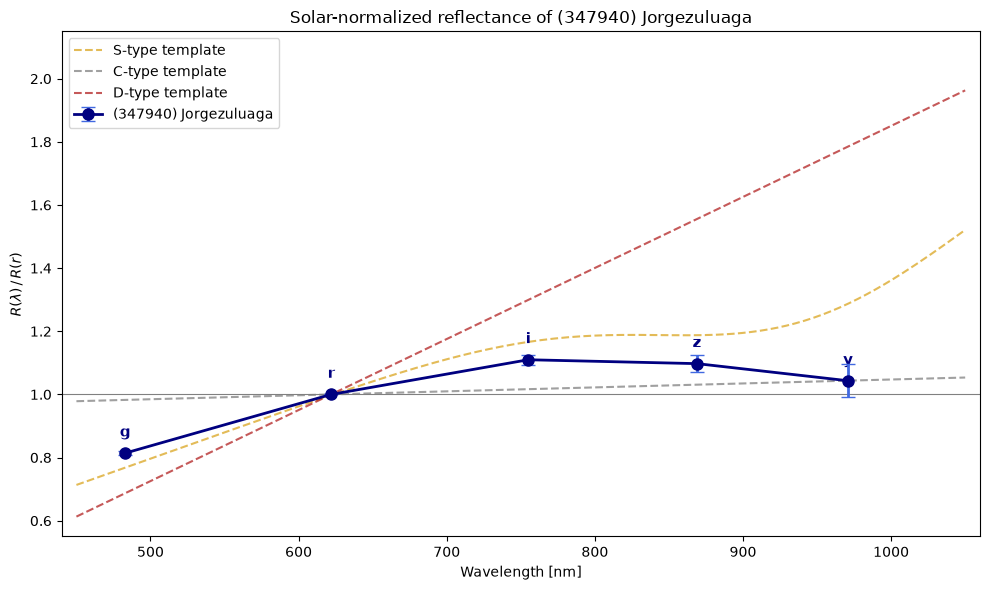

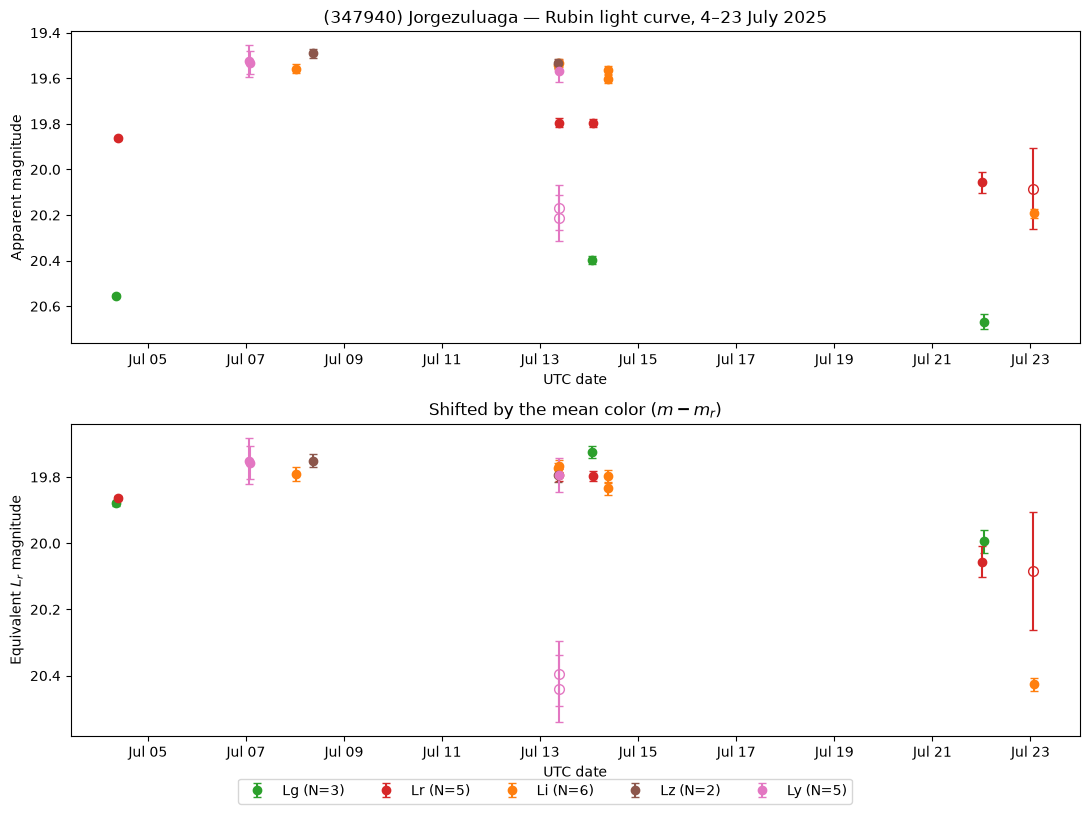

Observations: 21. Open circles: rmsmag > 0.08 mag.


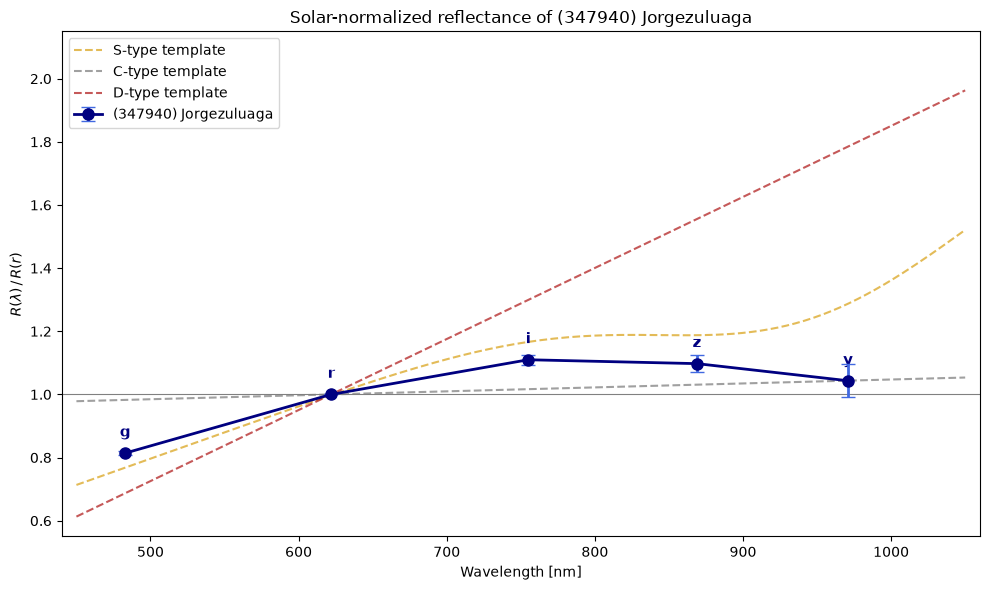

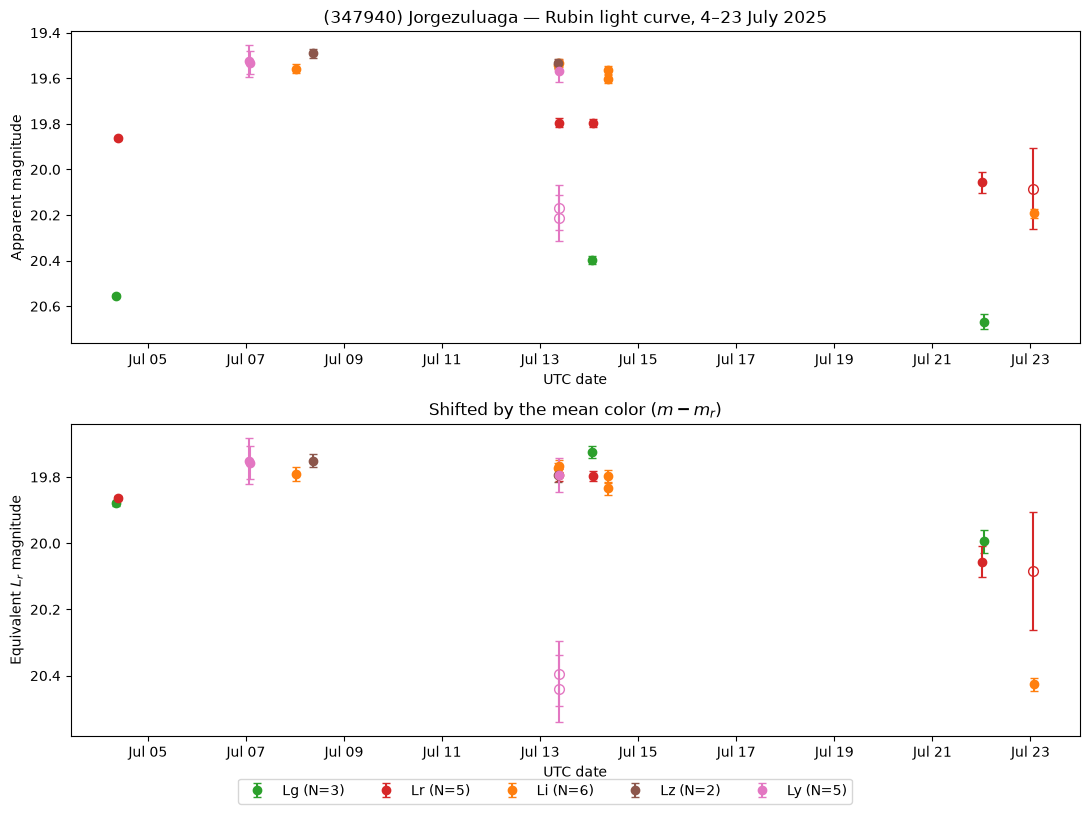

In [9]:
# Same-night colors relative to Lr. Drop rmsmag > 0.08 (two Ly and one Lr).
good = df_obj[df_obj['rmsmag'] <= 0.08]
color_samples = {b: [] for b in order if b != 'Lr'}
for _, g in good.groupby('night'):
    gr = g[g.band == 'Lr']
    if len(gr) == 0:
        continue
    mr, sr = wmean(gr['mag'], gr['rmsmag'])
    for b in color_samples:
        sub = g[g.band == b]
        if len(sub) == 0:
            continue
        mb, sb = wmean(sub['mag'], sub['rmsmag'])
        color_samples[b].append((mb - mr, np.sqrt(sb**2 + sr**2)))

spec = [('Lr', wavelengths['Lr'], 1.0, 0.0)]
offsets = {'Lr': 0.0}
for b, samples in color_samples.items():
    cols = np.array([s[0] for s in samples])
    errs = np.array([s[1] for s in samples])
    cmean, cerr = wmean(cols, errs)
    excess = cmean - solar_color[b]
    refl = 10.0 ** (-0.4 * excess)
    refl_err = refl * 0.4 * np.log(10.0) * cerr
    spec.append((b, wavelengths[b], refl, refl_err))
    offsets[b] = cmean
    print(f'{b}: (m-mr) = {cmean:.3f} ± {cerr:.3f}   R = {refl:.3f} ± {refl_err:.3f}   nights = {len(samples)}')
spec = sorted(spec, key=lambda x: x[1])

fig, ax = plt.subplots(figsize=(10, 6))
w = np.linspace(450, 1050, 200)
ax.plot(w, 1.0 + 0.5 * (w - 622) / 300.0 - 0.3 * np.exp(-((w - 950) / 150.0) ** 2),
        '--', color='goldenrod', alpha=0.75, label='S-type template')
ax.plot(w, 1.0 + 0.05 * (w - 622) / 400.0, '--', color='gray', alpha=0.75, label='C-type template')
ax.plot(w, 1.0 + 0.9 * (w - 622) / 400.0, '--', color='firebrick', alpha=0.75, label='D-type template')
ax.errorbar([s[1] for s in spec], [s[2] for s in spec], yerr=[s[3] for s in spec],
            fmt='o-', color='navy', ecolor='royalblue', elinewidth=2, capsize=5,
            markersize=8, linewidth=2, zorder=5, label='(347940) Jorgezuluaga')
for b, wl, refl, err in spec:
    ax.annotate(short[b], (wl, refl), textcoords='offset points', xytext=(0, 12),
                ha='center', fontsize=11, fontweight='bold', color='navy')
ax.axhline(1.0, color='0.5', lw=0.8, zorder=0)
ax.set_title('Solar-normalized reflectance of (347940) Jorgezuluaga')
ax.set_xlabel('Wavelength [nm]')
ax.set_ylabel(r'$R(\lambda)\,/\,R(r)$')
ax.set_xlim(440, 1060)
ax.set_ylim(0.55, 2.15)
ax.legend(frameon=True, loc='upper left')
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, 'jorgezuluaga_spectrum.png'), dpi=150)
display(fig)

df_obj['mag_r'] = df_obj['mag'] - df_obj['band'].map(offsets)
low_snr = df_obj['rmsmag'] > 0.08

fig, axes = plt.subplots(2, 1, figsize=(11, 8))
for ax, column, ylabel, title in (
    (axes[0], 'mag', 'Apparent magnitude',
     '(347940) Jorgezuluaga — Rubin light curve, 4–23 July 2025'),
    (axes[1], 'mag_r', r'Equivalent $L_r$ magnitude',
     r'Shifted by the mean color $(m - m_r)$'),
):
    for b in order:
        sub = df_obj[(df_obj.band == b) & ~low_snr]
        bad = df_obj[(df_obj.band == b) & low_snr]
        ax.errorbar(sub['obstime'], sub[column], yerr=sub['rmsmag'], fmt='o',
                    color=band_colors[b], label=f'{b} (N={len(sub) + len(bad)})',
                    markersize=6, capsize=3)
        if len(bad):
            ax.errorbar(bad['obstime'], bad[column], yerr=bad['rmsmag'], fmt='o',
                        color=band_colors[b], mfc='none', markersize=7, capsize=3)
    ax.invert_yaxis()
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
    ax.set_xlabel('UTC date')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=5, frameon=True, loc='lower center', bbox_to_anchor=(0.5, -0.02))
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, 'jorgezuluaga_lightcurve.png'), dpi=150, bbox_inches='tight')
display(fig)
print(f'Observations: {len(df_obj)}. Open circles: rmsmag > 0.08 mag.')